# Large-scale evaluation on random dev tiles: 3 best classical methods + 2 consensus + U-Net

2000 randomly sampled tiles from the dev set (different from the `best500` tiles used to develop and tune the methods -- this is an out-of-sample check on a larger, less curated set). Evaluated: `B_aspect` (watershed + aspect), `C_flow_accum` (flow accumulation), `E_flow_dir` (flow direction) -- our three strongest classical methods -- plus the two consensus combinations, plus the trained U-Net (circle-and-arc extraction) as an external comparison. All restricted to the 5-60px working range, same as before.

In [1]:
import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from scipy import ndimage
from skimage.segmentation import watershed
from skimage.measure import regionprops, label
from skimage.filters import sobel
from skimage.morphology import h_minima
import topotoolbox as tt3

import torch
import torch.nn as nn
from scipy.optimize import least_squares
from sklearn.cluster import DBSCAN


## Config -- paths, sample size, pixel range

In [2]:
DEV_IMAGES   = 'data/dev_images.hdf5'
DEV_CRATERS  = 'data/dev_craters.hdf5'
UNET_WEIGHTS = 'crater_unet_best.pt'   # trained in the companion repo, see README

N_SAMPLE = 2000
RANDOM_SEED = 42 # fixed so the sample is reproducible
SCAN_R_MIN, SCAN_R_MAX = 1, 60 # wider than the main notebook: includes the smallest craters

## Load 2000 random dev tiles

In [3]:
with h5py.File(DEV_IMAGES, 'r') as fh:
    n_total = fh['input_images'].shape[0]
print(f'{n_total} tiles available in dev set')

rng = np.random.default_rng(RANDOM_SEED)
sample_idx = np.sort(rng.choice(n_total, size=N_SAMPLE, replace=False)) # sorted -> faster h5py fancy indexing

eval_tiles = []
with h5py.File(DEV_IMAGES, 'r') as fh, pd.HDFStore(DEV_CRATERS, 'r') as store:
    for j in sample_idx:
        eval_tiles.append({
            'idx': int(j),
            'dem': fh['input_images'][j].astype('float32'),
            'craters': store[f'/img_{j:05d}'],
        })
print(f'loaded {len(eval_tiles)} random tiles (seed={RANDOM_SEED})')


30000 tiles available in dev set


loaded 2000 random tiles (seed=42)


## Resolution spread across the full dev dataset

Uses only the per-tile metadata (`longlat_bounds`, `pix_distortion_coefficient`), not the full DEM arrays -- cheap even over the entire dataset, not just the 2000-tile sample.

In [4]:
MOON_KM_PER_DEG = 30.32
TILE_SIZE = 256

def km_per_pix(longlat_bounds, distortion):
    lon_min, lon_max, lat_min, lat_max = longlat_bounds
    lat_centre = (lat_min + lat_max) / 2
    lon_range = lon_max - lon_min
    km_per_deg = MOON_KM_PER_DEG * np.cos(np.radians(lat_centre))
    return (lon_range / TILE_SIZE) * km_per_deg * float(distortion)

with h5py.File(DEV_IMAGES, 'r') as fh:
    ll_grp = fh['longlat_bounds']
    di_grp = fh['pix_distortion_coefficient']
    n_all = fh['input_images'].shape[0]
    all_res = np.zeros(n_all, dtype=np.float32)
    for i in range(n_all):
        ll = ll_grp[f'img_{i:05d}'][()]
        di = di_grp[f'img_{i:05d}'][()][0]
        all_res[i] = km_per_pix(ll, di)

print(f"tiles in full dev set: {n_all}")
print(f"best (finest) resolution:  {all_res.min():.4f} km/px")
print(f"worst (coarsest) resolution: {all_res.max():.4f} km/px")
print(f"mean: {all_res.mean():.4f} km/px")
for p in [5, 25, 50, 75, 95]:
    print(f"  {p}th percentile: {np.percentile(all_res, p):.4f} km/px")


tiles in full dev set: 30000
best (finest) resolution:  0.1200 km/px
worst (coarsest) resolution: 2.9986 km/px
mean: 0.9217 km/px
  5th percentile: 0.2092 km/px
  25th percentile: 0.3576 km/px
  50th percentile: 0.6887 km/px
  75th percentile: 1.3383 km/px
  95th percentile: 2.3395 km/px


## Basic functions (masking, smoothing, normalize, NMS, matching)

In [5]:
SIGMA_SMOOTH = 3.0
BORDER_ERODE = 3

def raw_data_mask(dem, nodata_value=0):
    return dem != nodata_value

def valid_data_mask(dem, nodata_value=0):
    return ndimage.binary_erosion(raw_data_mask(dem, nodata_value), iterations=BORDER_ERODE)

def masked_gaussian(dem, smoothing_mask, sigma):
    dem_masked = np.where(smoothing_mask, dem, 0.0)
    num = ndimage.gaussian_filter(dem_masked, sigma=sigma)
    den = ndimage.gaussian_filter(smoothing_mask.astype(float), sigma=sigma)
    return num / (den + 1e-8)

def normalize(x, invert=False, mask=None):
    vals = x[mask] if mask is not None else x
    lo, hi = np.percentile(vals, [5, 95])
    n = np.clip((x - lo) / (hi - lo + 1e-8), 0, 1)
    return 1 - n if invert else n

def circle_nms(detections, overlap_thresh=0.6):
    if not detections:
        return []
    dets = sorted(detections, key=lambda d: -d[3])
    keep = []
    for cy, cx, r, s in dets:
        if not any(np.hypot(cy-ky, cx-kx) < (r+kr)*overlap_thresh for ky, kx, kr, ks in keep):
            keep.append((cy, cx, r, s))
    return keep

# matches detections against the catalogue, restricted to SCAN_R_MIN-SCAN_R_MAX on BOTH sides --
# catalogue craters outside the range don't count toward recall, detections outside the range
# don't count toward precision (they were never in scope to begin with)
def match_ranged(dets, cat, D_xy=1.8, D_r=1.0):
    truth = [(c['x'], c['y'], c['Diameter (pix)']/2) for _, c in cat.iterrows()
             if SCAN_R_MIN <= c['Diameter (pix)']/2 <= SCAN_R_MAX]
    dets = [d for d in dets if SCAN_R_MIN <= d[2] <= SCAN_R_MAX]
    matched = set()
    tp = 0
    for cy, cx, r, s in sorted(dets, key=lambda d: -d[3]):
        for k, (tx, ty, tr) in enumerate(truth):
            if k in matched:
                continue
            if ((cx-tx)**2+(cy-ty)**2)/min(r,tr)**2 < D_xy and abs(r-tr)/min(r,tr) < D_r:
                tp += 1
                matched.add(k)
                break
    fp = len(dets) - tp
    fn = len(truth) - tp
    return tp, fp, fn

def evaluate_method(detect_fn, tiles=eval_tiles, label=None, D_xy=1.8, D_r=1.0):
    TP=FP=FN=0
    for t in tiles:
        dets = detect_fn(t['dem'])
        tp, fp, fn = match_ranged(dets, t['craters'], D_xy, D_r)
        TP+=tp; FP+=fp; FN+=fn
    p = TP/(TP+FP+1e-9)
    r = TP/(TP+FN+1e-9)
    f1 = 2*p*r/(p+r+1e-9)
    print(f"=== {label or 'result'} ===")
    print(f"precision : {p:.2f}")
    print(f"recall    : {r:.2f}")
    print(f"F1        : {f1:.2f}")
    print(f"TP={TP}   FP={FP}   FN={FN}")
    return p, r, f1


## Method B: Sobel edge + watershed + aspect filter

In [6]:
B_SOFT_THRESHOLD_PCT = 60
B_H_MIN = 0.18
B_MIN_AREA_PX = 2
B_MAX_AREA_PX = int(np.pi * SCAN_R_MAX**2)
B_MIN_CIRCULARITY = 0.5
B_MIN_INWARD = 0.15

def sobel_edge(dem, valid_mask):
    return sobel(dem) * valid_mask

def soft_threshold(x, valid_mask, percentile=B_SOFT_THRESHOLD_PCT):
    cutoff = np.percentile(x[valid_mask], percentile)
    return np.where(x > cutoff, x, 0.0) * valid_mask

def circularity(area, perimeter):
    perimeter = perimeter if perimeter > 0 else 1e-6
    return 4*np.pi*area / (perimeter**2)

def watershed_on_gradient(score_rim, valid_mask):
    edge_search = np.where(valid_mask, score_rim, 1.0)
    minima = h_minima(edge_search, B_H_MIN) & valid_mask
    markers, _ = ndimage.label(minima)
    segments = watershed(edge_search, markers, mask=valid_mask)
    detections = []
    for region in regionprops(segments):
        if region.area < B_MIN_AREA_PX or region.area > B_MAX_AREA_PX:
            continue
        circ = circularity(region.area, region.perimeter)
        if circ < B_MIN_CIRCULARITY:
            continue
        cy, cx = region.centroid
        detections.append((cy, cx, np.sqrt(region.area/np.pi), circ))
    return circle_nms(detections)

def detect_B_watershed(dem):
    raw_mask = raw_data_mask(dem)
    valid_mask = valid_data_mask(dem)
    dem_smooth = masked_gaussian(dem, raw_mask, SIGMA_SMOOTH)
    edge = sobel_edge(dem_smooth, valid_mask)
    score_rim = soft_threshold(normalize(edge, mask=valid_mask), valid_mask)
    return watershed_on_gradient(score_rim, valid_mask)

def aspect_inward_consistency(dem_smooth, cy, cx, r, valid_mask, n_samples=24):
    dy, dx = np.gradient(dem_smooth)
    angles = np.linspace(0, 2*np.pi, n_samples, endpoint=False)
    inward = []
    for a in angles:
        py = int(round(cy + r*np.sin(a)))
        px = int(round(cx + r*np.cos(a)))
        if not (0 <= py < dem_smooth.shape[0] and 0 <= px < dem_smooth.shape[1]):
            continue
        if not valid_mask[py, px]:
            continue
        gy, gx = -dy[py, px], -dx[py, px]
        norm = np.hypot(gy, gx) + 1e-9
        gy, gx = gy/norm, gx/norm
        iy, ix = (cy - py), (cx - px)
        inorm = np.hypot(iy, ix) + 1e-9
        iy, ix = iy/inorm, ix/inorm
        inward.append(gy*iy + gx*ix)
    return np.mean(inward) if inward else 0.0

def filter_by_aspect(detections, dem_smooth, valid_mask, min_inward):
    kept = []
    for cy, cx, r, s in detections:
        if aspect_inward_consistency(dem_smooth, cy, cx, r, valid_mask) >= min_inward:
            kept.append((cy, cx, r, s))
    return kept

def detect_B_aspect(dem):
    raw_mask = raw_data_mask(dem)
    valid_mask = valid_data_mask(dem)
    dem_smooth = masked_gaussian(dem, raw_mask, SIGMA_SMOOTH)
    dets = detect_B_watershed(dem)
    return filter_by_aspect(dets, dem_smooth, valid_mask, min_inward=B_MIN_INWARD)


## Method C: Flow accumulation (fill-depth)

In [7]:
C_THRESHOLD_PERCENTILE = 90
C_MIN_AREA_PX = 2
C_MAX_AREA_PX = int(np.pi * SCAN_R_MAX**2)
C_MIN_CIRCULARITY = 0.3

def compute_relief(dem_smooth, raw_mask, valid_mask, sigma=10):
    trend = masked_gaussian(dem_smooth, raw_mask, sigma)
    return (dem_smooth - trend) * valid_mask

def fill_depressions(field, raw_mask):
    walled = np.where(raw_mask, field, field.max() + 1000).astype('float32')
    g = tt3.GridObject()
    g.z = walled
    g.cellsize = 60.0
    filled = g.fillsinks()
    return np.asarray(filled.z)

def compute_fill_depth(relief, raw_mask, valid_mask):
    filled = fill_depressions(relief, raw_mask)
    return (filled - relief) * valid_mask

def interior_blob_detect(signal, valid_mask):
    cutoff = np.percentile(signal[valid_mask], C_THRESHOLD_PERCENTILE)
    blob_binary = (signal > cutoff) & valid_mask
    labels, n_regions = ndimage.label(blob_binary)
    detections = []
    for region in regionprops(labels):
        if region.area < C_MIN_AREA_PX or region.area > C_MAX_AREA_PX:
            continue
        circ = circularity(region.area, region.perimeter)
        if circ < C_MIN_CIRCULARITY:
            continue
        cy, cx = region.centroid
        detections.append((cy, cx, np.sqrt(region.area/np.pi), circ))
    return circle_nms(detections)

def detect_C_flow_accum(dem):
    raw_mask = raw_data_mask(dem)
    valid_mask = valid_data_mask(dem)
    dem_smooth = masked_gaussian(dem, raw_mask, SIGMA_SMOOTH)
    relief = compute_relief(dem_smooth, raw_mask, valid_mask)
    depth = compute_fill_depth(relief, raw_mask, valid_mask)
    return interior_blob_detect(depth, valid_mask)


## Method E: Flow direction (D8 sinks)

In [8]:
E_MIN_REGION_PX = 1
E_DETECTION_THRESHOLD = 0.6

D8_OFFSETS = [(-1,-1),(-1,0),(-1,1),(0,-1),(0,1),(1,-1),(1,0),(1,1)]
D8_DISTS = [np.sqrt(2),1,np.sqrt(2),1,1,np.sqrt(2),1,np.sqrt(2)]

def slope_magnitude(dem, valid_mask):
    dy, dx = np.gradient(dem)
    return np.sqrt(dx**2 + dy**2) * valid_mask

def disk_mask(cy, cx, r, shape):
    y, x = np.ogrid[:shape[0], :shape[1]]
    return (y-cy)**2 + (x-cx)**2 <= r**2

def annulus_mask(cy, cx, r_in, r_out, shape):
    y, x = np.ogrid[:shape[0], :shape[1]]
    d2 = (y-cy)**2 + (x-cx)**2
    return (d2 >= r_in**2) & (d2 <= r_out**2)

def radius_scan_and_filter(candidates, score_int, score_rim, valid_mask,
                            radii=range(SCAN_R_MIN, 60, 1), detection_threshold=E_DETECTION_THRESHOLD):
    detections = []
    for cy, cx in candidates:
        best_r, best_score = None, -1
        for r in radii:
            k_mask = disk_mask(cy, cx, 0.7*r, score_int.shape) & valid_mask
            if not k_mask.any():
                continue
            kern = score_int[k_mask].mean()
            ann_mask = annulus_mask(cy, cx, 0.8*r, 1.2*r, score_int.shape) & valid_mask
            if not ann_mask.any():
                continue
            ring = score_rim[ann_mask].mean()
            total = 0.5*kern + 0.5*ring
            if total > best_score:
                best_score, best_r = total, r
        if best_score is not None and best_score > detection_threshold:
            detections.append((cy, cx, best_r, best_score))
    return circle_nms(detections)

def d8_flow_direction(filled_dem, valid_mask):
    direction = np.full(filled_dem.shape, -1, dtype=int)
    best_drop = np.zeros(filled_dem.shape)
    for k, (dy, dx) in enumerate(D8_OFFSETS):
        shifted = np.roll(np.roll(filled_dem, -dy, axis=0), -dx, axis=1)
        drop = (filled_dem - shifted) / D8_DISTS[k]
        valid_neighbour = np.roll(np.roll(valid_mask, -dy, axis=0), -dx, axis=1)
        better = (drop > best_drop) & valid_neighbour & valid_mask
        direction[better] = k
        best_drop = np.where(better, drop, best_drop)
    return direction

def detect_E_flow_direction(dem):
    raw_mask = raw_data_mask(dem)
    valid_mask = valid_data_mask(dem)
    dem_smooth = masked_gaussian(dem, raw_mask, SIGMA_SMOOTH)
    relief = compute_relief(dem_smooth, raw_mask, valid_mask)
    direction = d8_flow_direction(dem_smooth, valid_mask)
    sinks = (direction == -1) & valid_mask
    labels, n = ndimage.label(sinks)
    candidates = []
    for region_id in range(1, n+1):
        region_mask = labels == region_id
        if region_mask.sum() < E_MIN_REGION_PX:
            continue
        cy, cx = ndimage.center_of_mass(region_mask)
        candidates.append((int(round(cy)), int(round(cx))))
    score_int = normalize(relief, invert=True, mask=valid_mask)
    score_rim = normalize(slope_magnitude(dem_smooth, valid_mask), mask=valid_mask)
    return radius_scan_and_filter(candidates, score_int, score_rim, valid_mask,
                                   detection_threshold=E_DETECTION_THRESHOLD)


## Consensus: two variants

In [9]:
def cluster_consensus(results_for_tile, min_agree, dist_frac=0.5):
    pooled = []
    for name, dets in results_for_tile.items():
        for cy, cx, r, s in dets:
            pooled.append((cy, cx, r, s, name))
    used = [False]*len(pooled)
    consensus = []
    for i, (cy, cx, r, s, name) in enumerate(pooled):
        if used[i]:
            continue
        cluster = [(cy, cx, r, name)]
        used[i] = True
        for j in range(i+1, len(pooled)):
            if used[j]:
                continue
            cy2, cx2, r2, s2, name2 = pooled[j]
            if np.hypot(cy-cy2, cx-cx2) < dist_frac*(r+r2):
                cluster.append((cy2, cx2, r2, name2))
                used[j] = True
        distinct_methods = {c[3] for c in cluster}
        if len(distinct_methods) >= min_agree:
            cys = np.median([c[0] for c in cluster])
            cxs = np.median([c[1] for c in cluster])
            rs = np.median([c[2] for c in cluster])
            consensus.append((cys, cxs, rs, len(distinct_methods)))
    return consensus

def detect_consensus(dem, methods, min_agree):
    results = {name: fn(dem) for name, fn in methods.items()}
    return cluster_consensus(results, min_agree)

CONSENSUS_METHODS_BE = {'B_aspect': detect_B_aspect, 'E_flow_dir': detect_E_flow_direction}
CONSENSUS_METHODS_BCE = {'B_aspect': detect_B_aspect, 'C_flow_accum': detect_C_flow_accum, 'E_flow_dir': detect_E_flow_direction}


## U-Net: model, weights, prediction on the same 2000 tiles

In [10]:
class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch,  out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1), nn.BatchNorm2d(out_ch), nn.ReLU(inplace=True),
        )
    def forward(self, x):
        return self.block(x)

class UNet(nn.Module):
    def __init__(self, in_ch=1, base=32):
        super().__init__()
        self.pool = nn.MaxPool2d(2)
        self.e1 = ConvBlock(in_ch,   base)
        self.e2 = ConvBlock(base,    base*2)
        self.e3 = ConvBlock(base*2,  base*4)
        self.e4 = ConvBlock(base*4,  base*8)
        self.b  = ConvBlock(base*8,  base*16)
        self.u4 = nn.ConvTranspose2d(base*16, base*8, 2, stride=2); self.d4 = ConvBlock(base*16, base*8)
        self.u3 = nn.ConvTranspose2d(base*8,  base*4, 2, stride=2); self.d3 = ConvBlock(base*8,  base*4)
        self.u2 = nn.ConvTranspose2d(base*4,  base*2, 2, stride=2); self.d2 = ConvBlock(base*4,  base*2)
        self.u1 = nn.ConvTranspose2d(base*2,  base,   2, stride=2); self.d1 = ConvBlock(base*2,  base)
        self.out = nn.Conv2d(base, 1, 1)

    def forward(self, x):
        c1 = self.e1(x)
        c2 = self.e2(self.pool(c1))
        c3 = self.e3(self.pool(c2))
        c4 = self.e4(self.pool(c3))
        b  = self.b(self.pool(c4))
        x = self.d4(torch.cat([self.u4(b), c4], dim=1))
        x = self.d3(torch.cat([self.u3(x), c3], dim=1))
        x = self.d2(torch.cat([self.u2(x), c2], dim=1))
        x = self.d1(torch.cat([self.u1(x), c1], dim=1))
        return torch.sigmoid(self.out(x))

device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = UNet().to(device)
model.load_state_dict(torch.load(UNET_WEIGHTS, map_location=device))
model.eval()
print('model loaded on', device)


model loaded on cuda


In [11]:
# same 2000 tiles as the classical methods, normalized 0-1 the way the model was trained
X_unet = np.stack([t['dem'] for t in eval_tiles]) / 255.0
X_unet = X_unet[..., np.newaxis].astype('float32')

def to_tensor(X):
    return torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()

@torch.no_grad()
def predict(X, batch=16):
    model.eval()
    out = []
    for i in range(0, len(X), batch):
        xb = to_tensor(X[i:i+batch]).to(device)
        out.append(model(xb).cpu().numpy()[:, 0])
    return np.concatenate(out)

preds = predict(X_unet)
print('predicted masks:', preds.shape, '| value range', round(float(preds.min()),3), '-', round(float(preds.max()),3))


predicted masks: (2000, 256, 256) | value range 0.0 - 1.0


## Circle-and-arc fitting extractor (from the U-Net evaluation notebook)

In [12]:
R_MIN_PX = 1
R_MAX_PX = 60

def get_radius_range(tile_idx):
    return R_MIN_PX, R_MAX_PX

def circle_iou(d1, d2):
    x1, y1, r1 = d1[0], d1[1], d1[2]
    x2, y2, r2 = d2[0], d2[1], d2[2]
    dist = np.sqrt((x1-x2)**2 + (y1-y2)**2)
    if dist >= r1 + r2: return 0.0
    if dist <= abs(r1 - r2):
        smaller = min(r1, r2)**2
        larger  = max(r1, r2)**2
        return (np.pi * smaller) / (np.pi * larger + 1e-8)
    r1_sq  = r1**2
    r2_sq  = r2**2
    d_sq   = dist**2
    cos_a1 = np.clip((d_sq+r1_sq-r2_sq)/(2*dist*r1+1e-8), -1, 1)
    cos_a2 = np.clip((d_sq+r2_sq-r1_sq)/(2*dist*r2+1e-8), -1, 1)
    a1     = np.arccos(cos_a1)
    a2     = np.arccos(cos_a2)
    intersection = (r1_sq*(a1-np.sin(2*a1)/2) + r2_sq*(a2-np.sin(2*a2)/2))
    union = np.pi*(r1_sq+r2_sq) - intersection
    return intersection / (union + 1e-8)

def fit_circle_to_points(x_points, y_points):
    if len(x_points) < 5: return None
    cx0 = np.mean(x_points)
    cy0 = np.mean(y_points)
    r0  = np.mean(np.sqrt((x_points-cx0)**2 + (y_points-cy0)**2))
    if r0 < 1: return None
    def residuals(params):
        cx, cy, r = params
        dist = np.sqrt((x_points-cx)**2 + (y_points-cy)**2)
        return dist - r
    try:
        result    = least_squares(residuals, x0=[cx0, cy0, r0], method='lm', max_nfev=500)
        cx, cy, r = result.x
        residual  = np.mean(np.abs(result.fun))
        return cx, cy, abs(r), residual
    except Exception: return None

def fit_circle_from_arc(x_points, y_points):
    if len(x_points) < 5: return None
    if max(x_points.max()-x_points.min(), y_points.max()-y_points.min()) < 5: return None
    return fit_circle_to_points(x_points, y_points)

def fit_circle_to_points_weighted(x_points, y_points, weights=None):
    if len(x_points) < 5: return None
    if weights is None: weights = np.ones(len(x_points))
    weights = weights / (weights.sum() + 1e-8)
    cx0 = np.sum(weights * x_points)
    cy0 = np.sum(weights * y_points)
    r0  = np.mean(np.sqrt((x_points-cx0)**2 + (y_points-cy0)**2))
    if r0 < 1: return None
    def residuals(params):
        cx, cy, r = params
        dist = np.sqrt((x_points-cx)**2 + (y_points-cy)**2)
        return (dist - r) * weights * len(weights)
    try:
        result    = least_squares(residuals, x0=[cx0, cy0, r0], method='lm', max_nfev=500)
        cx, cy, r = result.x
        residual  = np.mean(np.abs(result.fun / (weights*len(weights)+1e-8)))
        return cx, cy, abs(r), residual
    except Exception:
        return None

def split_component(x_points, y_points, min_cluster_size=5):
    if len(x_points) < min_cluster_size * 2: return [(x_points, y_points)]
    coords = np.column_stack([x_points, y_points])
    db     = DBSCAN(eps=8, min_samples=min_cluster_size).fit(coords)
    labels = db.labels_
    groups = []
    for lab in set(labels):
        if lab == -1: continue
        mask = labels == lab
        if mask.sum() >= min_cluster_size: groups.append((x_points[mask], y_points[mask]))
    return groups if groups else [(x_points, y_points)]

def fit_two_circles(x_points, y_points):
    if len(x_points) < 15: return None
    x_mid  = np.median(x_points)
    y_mid  = np.median(y_points)
    left   = x_points <= x_mid
    right  = x_points > x_mid
    top    = y_points <= y_mid
    bot    = y_points > y_mid
    splits = []
    if left.sum() >= 5 and right.sum() >= 5: splits.append((left, right))
    if top.sum() >= 5 and bot.sum() >= 5: splits.append((top, bot))
    if not splits: return None
    best_result         = None
    best_total_residual = float('inf')
    for m1, m2 in splits:
        r1 = fit_circle_from_arc(x_points[m1], y_points[m1])
        r2 = fit_circle_from_arc(x_points[m2], y_points[m2])
        if r1 is None or r2 is None: continue
        total = (r1[3] + r2[3]) / 2
        if total < best_total_residual:
            best_total_residual = total
            best_result         = (r1, r2)
    return best_result

def detect_craters_from_mask(prob_mask, tile_idx, prob_threshold=0.3, min_pixels=10, max_residual=2.5,
                              min_coverage=0.25, max_radius_fraction=0.35, split_large=True,
                              split_threshold=200, try_two_circles=True):
    r_min, r_max = get_radius_range(tile_idx)
    r_abs_max = int(256 * max_radius_fraction)
    binary  = (prob_mask > prob_threshold).astype(np.uint8)
    labeled = label(binary, connectivity=2)
    regions = regionprops(labeled)
    detections = []
    for region in regions:
        if region.area < min_pixels: continue
        coords = region.coords
        y_pts  = coords[:, 0].astype(float)
        x_pts  = coords[:, 1].astype(float)
        groups = split_component(x_pts, y_pts) if (split_large and region.area > split_threshold) else [(x_pts, y_pts)]
        for x_grp, y_grp in groups:
            if len(x_grp) < min_pixels: continue
            result = fit_circle_to_points(x_grp, y_grp)
            single_worked = False
            if result is not None:
                cx, cy, r, res = result
                margin   = r * 0.3
                expected = 2 * np.pi * r
                coverage = min(1.0, len(x_grp) / expected)
                if (r_min <= r <= min(r_max, r_abs_max) and res <= max_residual and
                        margin <= cx < 256-margin and margin <= cy < 256-margin and coverage >= min_coverage):
                    detections.append({'x': float(cx), 'y': float(cy), 'r': float(r), 'residual': float(res),
                                        'coverage': float(coverage), 'n_pixels': int(len(x_grp)), 'source': 'circle'})
                    single_worked = True
            if (not single_worked and try_two_circles and len(x_grp) >= r_min * 4):
                two = fit_two_circles(x_grp, y_grp)
                if two is not None:
                    for cx, cy, r, res in two:
                        if not (r_min <= r <= min(r_max, r_abs_max)): continue
                        if res > max_residual * 1.5: continue
                        if not (0 <= cx < 256 and 0 <= cy < 256): continue
                        expected = 2 * np.pi * r
                        coverage = min(1.0, len(x_grp)/2 / expected)
                        if coverage < min_coverage * 0.5: continue
                        detections.append({'x': float(cx), 'y': float(cy), 'r': float(r), 'residual': float(res),
                                            'coverage': float(coverage), 'n_pixels': int(len(x_grp)//2), 'source': 'circle_pair'})
    return detections

def subtract_detected_rims(prob_mask, detections, tile_idx, rim_thickness=4):
    residual = prob_mask.copy()
    H, W = prob_mask.shape
    y_grid, x_grid = np.ogrid[:H, :W]
    for d in detections:
        cx, cy, r = d['x'], d['y'], d['r']
        dist_centre = np.sqrt((x_grid-cx)**2 + (y_grid-cy)**2)
        dist_rim = np.abs(dist_centre - r)
        residual[dist_rim <= rim_thickness] = 0.0
    return residual

def detect_arcs_improved(residual_mask, tile_idx, prob_threshold=0.2, min_pixels=8, max_residual=6.0,
                          min_span=6, min_coverage=0.10, max_radius_fraction=0.45, split_large=True, split_threshold=150):
    r_min, r_max = get_radius_range(tile_idx)
    r_abs_max = int(256 * max_radius_fraction)
    binary  = (residual_mask > prob_threshold).astype(np.uint8)
    labeled = label(binary, connectivity=2)
    regions = regionprops(labeled)
    detections = []
    for region in regions:
        if region.area < min_pixels: continue
        coords = region.coords
        y_pts = coords[:, 0].astype(float)
        x_pts = coords[:, 1].astype(float)
        if max(x_pts.max()-x_pts.min(), y_pts.max()-y_pts.min()) < min_span: continue
        groups = split_component(x_pts, y_pts) if (split_large and region.area > split_threshold) else [(x_pts, y_pts)]
        for x_grp, y_grp in groups:
            if len(x_grp) < min_pixels: continue
            w_grp = np.array([residual_mask[int(y), int(x)] for x, y in zip(x_grp, y_grp)])
            result = fit_circle_to_points_weighted(x_grp, y_grp, w_grp)
            if result is None: result = fit_circle_from_arc(x_grp, y_grp)
            if result is None: continue
            cx, cy, r, res = result
            if r < r_min or r > r_abs_max: continue
            if res > max_residual: continue
            if not (0 <= cx < 256 and 0 <= cy < 256): continue
            expected = 2 * np.pi * r
            coverage = min(1.0, len(x_grp) / expected)
            if coverage < min_coverage: continue
            detections.append({'x': float(cx), 'y': float(cy), 'r': float(r), 'residual': float(res),
                                'coverage': float(coverage), 'n_pixels': int(len(x_grp)), 'source': 'arc'})
    return detections

def detect_all_craters(prob_mask, tile_idx):
    det_circles = detect_craters_from_mask(prob_mask, tile_idx=tile_idx, prob_threshold=0.5, min_pixels=10,
                                            max_residual=2.5, min_coverage=0.25, max_radius_fraction=0.35,
                                            split_large=True, split_threshold=200, try_two_circles=True)
    residual_mask = subtract_detected_rims(prob_mask, det_circles, tile_idx, rim_thickness=4)
    det_arcs = detect_arcs_improved(residual_mask, tile_idx=tile_idx, prob_threshold=0.4, min_pixels=5,
                                     max_residual=6.0, min_span=6, min_coverage=0.10, max_radius_fraction=0.45,
                                     split_large=True, split_threshold=150)
    all_raw = det_circles + det_arcs
    unified = [(d['x'], d['y'], d['r'], max(0.0, 1.0 - d['residual']*0.1), d['source'], d['coverage'], d['residual'])
               for d in all_raw]
    unified = sorted(unified, key=lambda d: d[3], reverse=True)
    kept = []
    while unified:
        best = unified.pop(0)
        kept.append(best)
        unified = [d for d in unified if circle_iou(best, d) < 0.3]
    final = [{'x': x, 'y': y, 'r': r, 'nms_score': s, 'source': src, 'coverage': true_cov, 'residual': true_res}
             for x, y, r, s, src, true_cov, true_res in kept]
    return final, residual_mask

# wrap as an extractor with the SAME interface as the classical detect_ functions: dem -> list of (cy, cx, r, score)
# note: unlike the classical methods this doesn't take the raw DEM -- it needs the tile's INDEX in `preds`,
# so it's wired up per-tile in the evaluation loop below instead of being a bare dem->detections function
def extract_circlearc(tile_array_idx):
    dets, _ = detect_all_craters(preds[tile_array_idx], tile_idx=tile_array_idx)
    return [(d['y'], d['x'], d['r'], d.get('coverage', 1.0)) for d in dets] # (cy, cx, r, score) to match our convention


## Evaluate all 6 -- 3 best classical + 2 consensus + U-Net

In [13]:
evaluate_method(detect_B_aspect, label='B_aspect')

print()
evaluate_method(detect_C_flow_accum, label='C_flow_accum')

print()
evaluate_method(detect_E_flow_direction, label='E_flow_dir')

print()
evaluate_method(lambda dem: detect_consensus(dem, CONSENSUS_METHODS_BE, 2), label='consensus_BE (both required)')

print()
evaluate_method(lambda dem: detect_consensus(dem, CONSENSUS_METHODS_BCE, 3), label='consensus_BCE (all three required)')


=== B_aspect ===
precision : 0.39
recall    : 0.18
F1        : 0.24
TP=12885   FP=20181   FN=60369



=== C_flow_accum ===
precision : 0.22
recall    : 0.16
F1        : 0.18
TP=11462   FP=41790   FN=61792



=== E_flow_dir ===
precision : 0.30
recall    : 0.17
F1        : 0.22
TP=12796   FP=30069   FN=60458



=== consensus_BE (both required) ===
precision : 0.53
recall    : 0.14
F1        : 0.23
TP=10562   FP=9471   FN=62692



=== consensus_BCE (all three required) ===
precision : 0.62
recall    : 0.14
F1        : 0.22
TP=9998   FP=6153   FN=63256


(0.6190328772211864, 0.13648401452480224, 0.2236563947601689)

In [14]:
# U-Net evaluated by array position (0..N_SAMPLE-1), not by detect_fn(dem) like the others,
# since its detections come from the already-computed preds array, not from the DEM directly
TP=FP=FN=0
for i, t in enumerate(eval_tiles):
    dets = extract_circlearc(i)
    tp, fp, fn = match_ranged(dets, t['craters'])
    TP+=tp; FP+=fp; FN+=fn
p = TP/(TP+FP+1e-9)
r = TP/(TP+FN+1e-9)
f1 = 2*p*r/(p+r+1e-9)
print("=== U-Net (circle-and-arc extraction) ===")
print(f"precision : {p:.2f}")
print(f"recall    : {r:.2f}")
print(f"F1        : {f1:.2f}")
print(f"TP={TP}   FP={FP}   FN={FN}")


=== U-Net (circle-and-arc extraction) ===
precision : 0.83
recall    : 0.46
F1        : 0.59
TP=33967   FP=7099   FN=39287


In [15]:
all_catalogue_radii = np.concatenate([t['craters']['Diameter (pix)'].values / 2 for t in eval_tiles])
in_range = (all_catalogue_radii >= SCAN_R_MIN) & (all_catalogue_radii <= SCAN_R_MAX)

print(f"catalogue craters pooled: {len(all_catalogue_radii)}")
print(f"min={all_catalogue_radii.min():.1f}px  max={all_catalogue_radii.max():.1f}px  mean={all_catalogue_radii.mean():.1f}px")
for p in [5, 25, 50, 75, 95]:
    print(f"  {p}th percentile: {np.percentile(all_catalogue_radii, p):.1f}px")
print()
print(f"our scan range: {SCAN_R_MIN}-{SCAN_R_MAX}px")
print(f"catalogue craters covered by that range: {in_range.mean()*100:.1f}%")

catalogue craters pooled: 76152
min=0.8px  max=996.5px  mean=5.3px
  5th percentile: 1.0px
  25th percentile: 1.6px
  50th percentile: 2.6px
  75th percentile: 5.1px
  95th percentile: 16.3px

our scan range: 1-60px
catalogue craters covered by that range: 96.2%


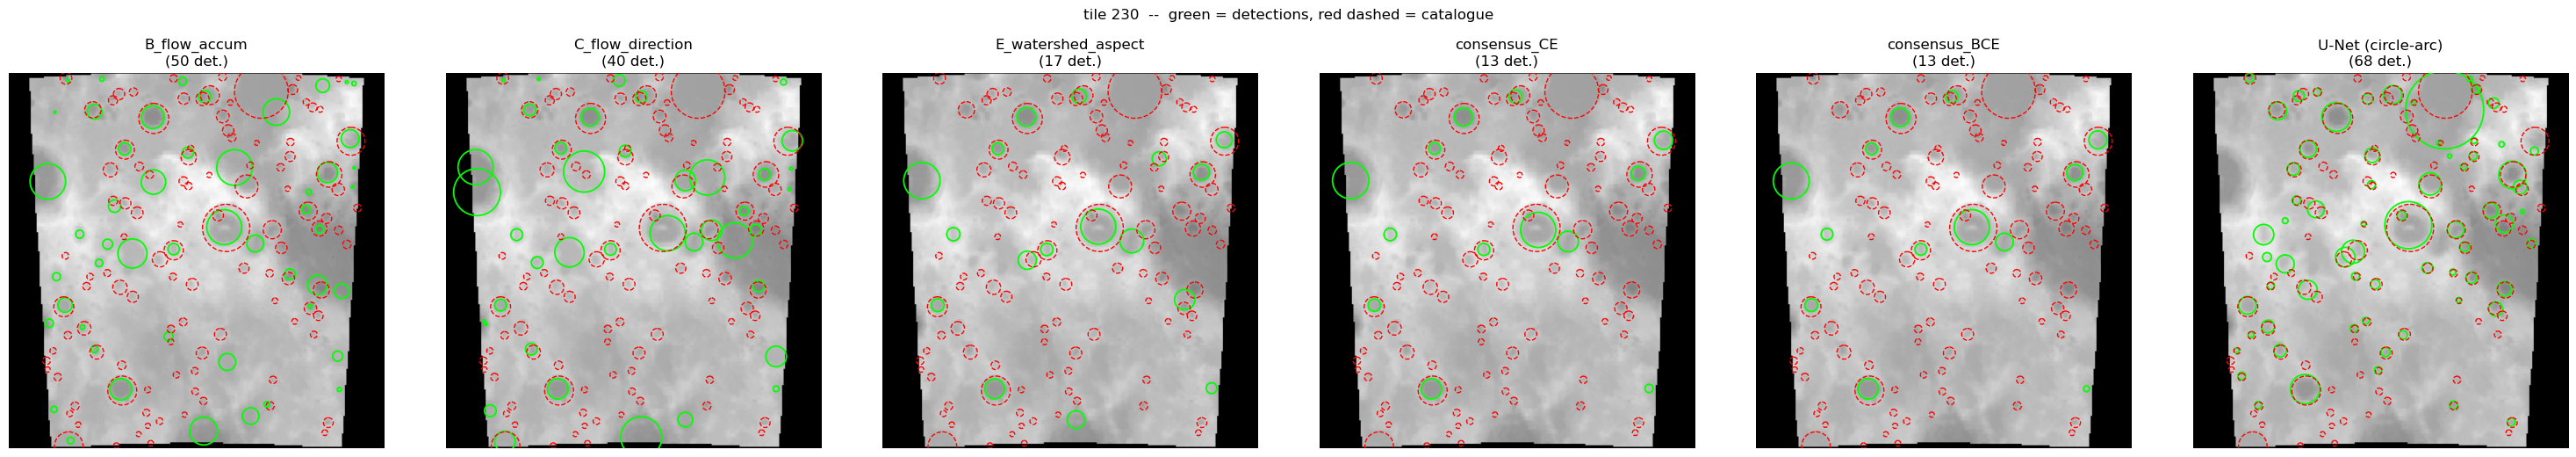

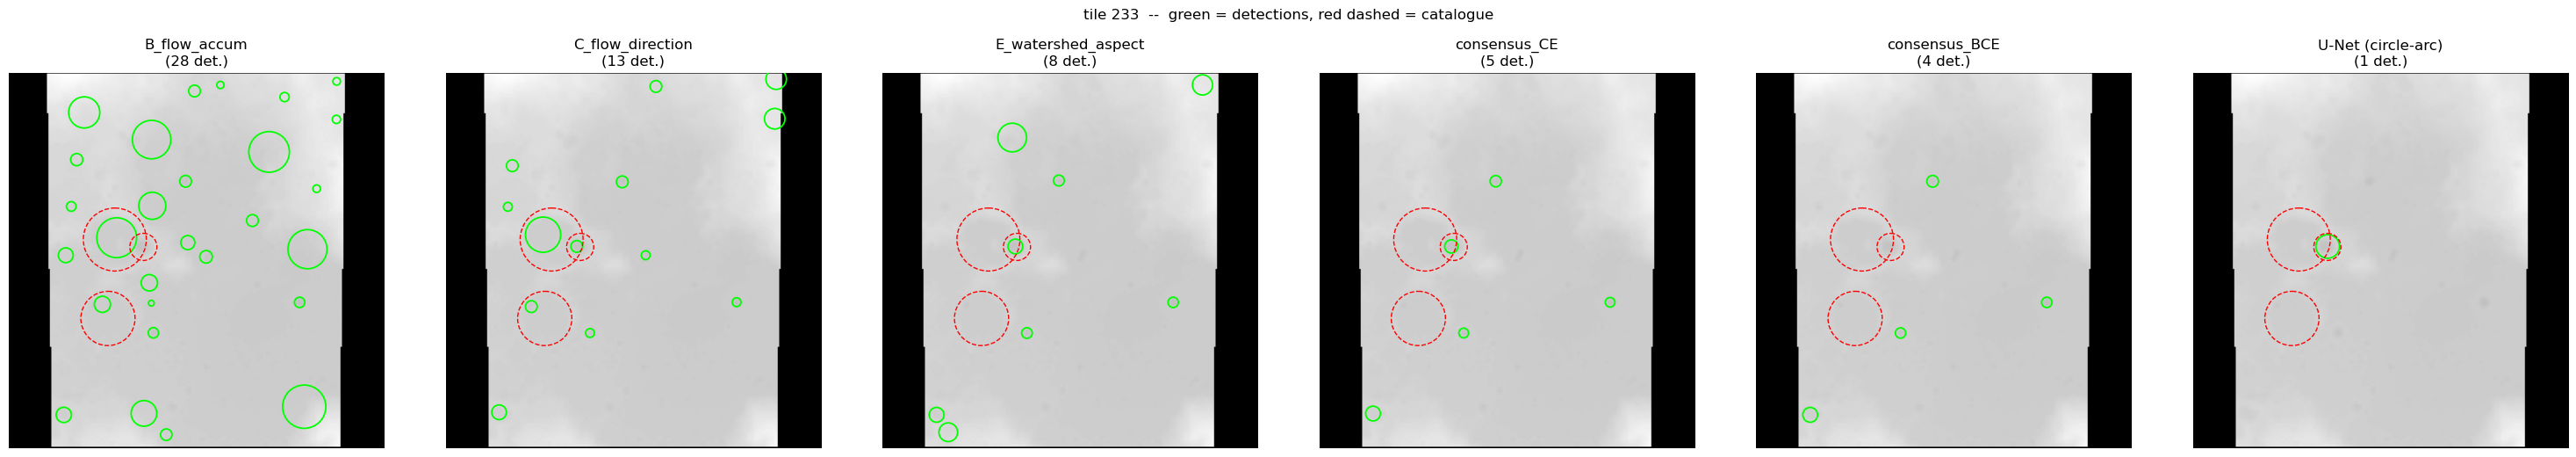

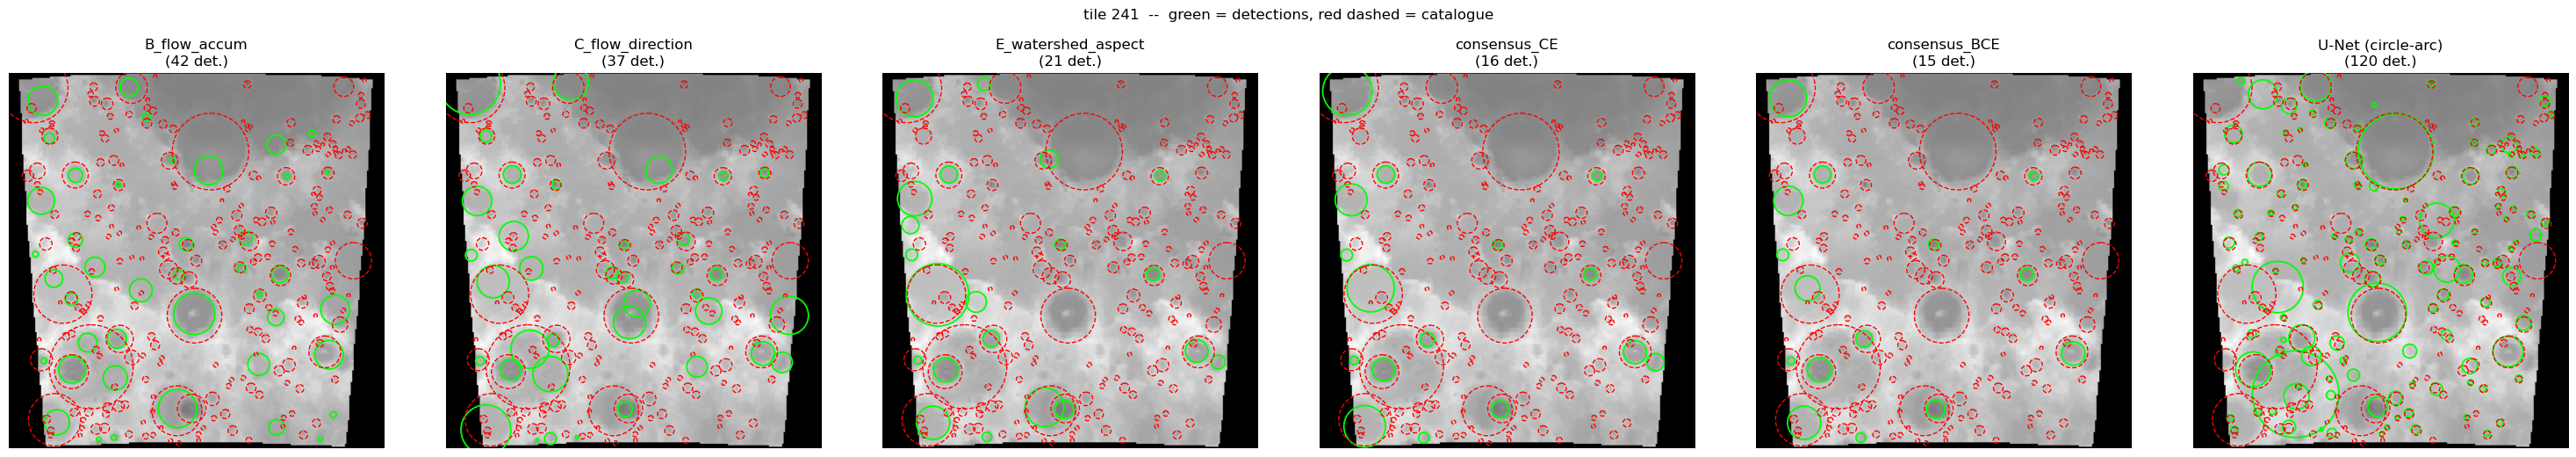

In [16]:
tile_to_array_idx = {t['idx']: i for i, t in enumerate(eval_tiles)}

DEMO_METHODS = {
    'B_flow_accum': detect_C_flow_accum,
    'C_flow_direction': detect_E_flow_direction,
    'E_watershed_aspect': detect_B_aspect,
    'consensus_CE': lambda dem: detect_consensus(dem, CONSENSUS_METHODS_BE, 2),
    'consensus_BCE': lambda dem: detect_consensus(dem, CONSENSUS_METHODS_BCE, 3),
    'U-Net (circle-arc)': None,
}

DEMO_TILES = eval_tiles[20:23]

demo_results = {}
for t in DEMO_TILES:
    row = {}
    for name, fn in DEMO_METHODS.items():
        if name == 'U-Net (circle-arc)':
            row[name] = extract_circlearc(tile_to_array_idx[t['idx']])
        else:
            row[name] = fn(t['dem'])
    demo_results[t['idx']] = row

def plot_tile_comparison(t):
    combo = demo_results[t['idx']]
    fig, ax = plt.subplots(1, len(combo), figsize=(5*len(combo), 5))
    for a, name in zip(ax, combo.keys()):
        a.imshow(t['dem'], cmap='gray')
        for cy, cx, r, s in combo[name]:
            a.add_patch(Circle((cx, cy), r, fill=False, color='lime', lw=1.3))
        for _, c in t['craters'].iterrows():
            a.add_patch(Circle((c['x'], c['y']), c['Diameter (pix)']/2,
                               fill=False, color='red', lw=1.0, linestyle='--'))
        a.set_title(f"{name}\n({len(combo[name])} det.)")
        a.axis('off')
    fig.suptitle(f"tile {t['idx']}  --  green = detections, red dashed = catalogue", y=1.03)
    plt.tight_layout()
    plt.show()

for t in DEMO_TILES:
    plot_tile_comparison(t)